In [3]:
# Povezivanje sa Google Drive-om
from google.colab import drive
drive.mount('/content/drive')

# Instalacija potrebnih biblioteka
!pip install -q torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu118
!pip install -q rasterio geopandas matplotlib albumentations tqdm

Mounted at /content/drive
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 22.3/22.3 MB 35.6 MB/s eta 0:00:00


In [4]:
import os
import numpy as np
import cv2
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import models
import albumentations as A
from albumentations.pytorch import ToTensorV2
from tqdm import tqdm
import matplotlib.pyplot as plt
import rasterio
from rasterio.features import shapes
import geopandas as gpd

# Postavljanje uređaja (GPU ako je dostupan, inače CPU)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Koristi se uređaj: {DEVICE}")

Koristi se uređaj: cuda


In [5]:
class WaterBodiesDataset(Dataset):
    """
    Klasa za učitavanje ortofoto snimaka i odgovarajućih maski.
    Prilagođena za imena maski oblika 'ime_slike_mask.png'.
    """
    def __init__(self, image_dir, mask_dir, transform=None):
        self.image_dir = image_dir
        self.mask_dir = mask_dir
        self.transform = transform
        self.images = os.listdir(image_dir)

    def __len__(self):
        return len(self.images)

    def __getitem__(self, index):
        img_name = self.images[index]
        img_path = os.path.join(self.image_dir, img_name)

        # Kreiranje imena maske na osnovu imena slike
        mask_name = img_name.replace('.png', '_mask.png')
        mask_path = os.path.join(self.mask_dir, mask_name)

        # Učitavanje slike i maske
        image = cv2.imread(img_path)
        image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
        mask = cv2.imread(mask_path, 0) # Učitavanje kao grayscale

        # Binarizacija maske: pikseli > 0 postaju 1 (voda), ostali su 0 (pozadina)
        if mask is not None:
            mask[mask > 0] = 1.0
        else:
            # Ako maska ne postoji, kreiraj praznu masku
            print(f"Upozorenje: Maska nije pronađena za sliku {img_name}. Kreira se prazna maska.")
            mask = np.zeros(image.shape[:2], dtype=np.float32)

        if self.transform is not None:
            augmentations = self.transform(image=image, mask=mask)
            image = augmentations["image"]
            mask = augmentations["mask"]
            # PyTorch očekuje masku tipa LongTensor za CrossEntropyLoss
            mask = mask.long()

        return image, mask

In [6]:
# Definicija augmentacija za trening i validaciju
train_transform = A.Compose(
    [
        A.Resize(512, 512),
        A.Rotate(limit=35, p=0.5),
        A.HorizontalFlip(p=0.5),
        A.VerticalFlip(p=0.5),
        A.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225],
            max_pixel_value=255.0,
        ),
        ToTensorV2(),
    ],
)

val_transform = A.Compose(
    [
        A.Resize(512, 512),
        A.Normalize(
            mean=[0.485, 0.456, 0.406],
            std=[0.229, 0.224, 0.225],
            max_pixel_value=255.0,
        ),
        ToTensorV2(),
    ],
)

# Putanje do vaših podataka na Google Drive-u
BASE_DIR = "/content/drive/MyDrive/DataSet/"
TRAIN_IMG_DIR = os.path.join(BASE_DIR, "train/images/")
TRAIN_MASK_DIR = os.path.join(BASE_DIR, "train/masks/")
VAL_IMG_DIR = os.path.join(BASE_DIR, "val/images/")
VAL_MASK_DIR = os.path.join(BASE_DIR, "val/masks/")
TEST_IMG_DIR = os.path.join(BASE_DIR, "test/images/")
TEST_MASK_DIR = os.path.join(BASE_DIR, "test/masks/")

--- Prikaz uzorka iz trening skupa ---


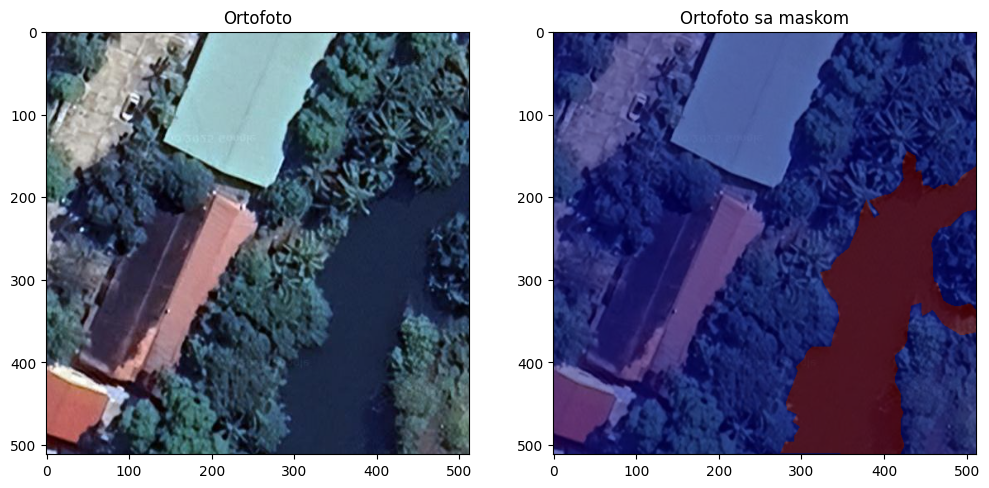

In [7]:
# Kreiranje Dataset i DataLoader objekata
train_dataset = WaterBodiesDataset(image_dir=TRAIN_IMG_DIR, mask_dir=TRAIN_MASK_DIR, transform=train_transform)
val_dataset = WaterBodiesDataset(image_dir=VAL_IMG_DIR, mask_dir=VAL_MASK_DIR, transform=val_transform)
test_dataset = WaterBodiesDataset(image_dir=TEST_IMG_DIR, mask_dir=TEST_MASK_DIR, transform=val_transform)

# >>> ISPRAVKA JE OVDE <<<
# Dodajemo 'drop_last=True' u train_loader da bismo izbegli batch-eve veličine 1.
train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    num_workers=2,
    drop_last=True  # Odbaci poslednji, nekompletan batch
)
val_loader = DataLoader(val_dataset, batch_size=4, shuffle=False, num_workers=2)
test_loader = DataLoader(test_dataset, batch_size=4, shuffle=False, num_workers=2)


# Funkcija za prikaz preklapanja maske i ortofotoa
def show_sample(image, mask):
    # Denormalizacija slike za prikaz
    inv_normalize = A.Normalize(
        mean=[-0.485/0.229, -0.456/0.224, -0.406/0.225],
        std=[1/0.229, 1/0.224, 1/0.225],
        max_pixel_value=1.0
    )
    # Prvo konvertujemo Tensor u NumPy niz, pa onda primenjujemo transformaciju
    image_numpy = image.permute(1, 2, 0).numpy()
    image_denormalized = inv_normalize(image=image_numpy)['image']

    plt.figure(figsize=(12, 6))
    plt.subplot(1, 2, 1)
    plt.imshow(image_denormalized)
    plt.title("Ortofoto")
    plt.subplot(1, 2, 2)
    plt.imshow(image_denormalized)
    # Prikaz maske sa providnošću. Maska je Tensor, pa je konvertujemo u numpy za prikaz.
    plt.imshow(mask.numpy(), cmap="jet", alpha=0.5)
    plt.title("Ortofoto sa maskom")
    plt.show()

# Prikaz jednog primera iz trening seta
print("--- Prikaz uzorka iz trening skupa ---")
try:
    image, mask = train_dataset[0]
    show_sample(image, mask)
except IndexError:
    print("Greška: Trening set je prazan. Proverite putanju do podataka i da li folder sadrži slike.")

In [8]:
def get_model(num_classes):
    # Učitavanje pre-treniranog DeepLabV3 modela
    model = models.segmentation.deeplabv3_resnet50(weights='DeepLabV3_ResNet50_Weights.DEFAULT')

    # Menjamo klasifikator da odgovara broju klasa našeg problema
    model.classifier[4] = nn.Conv2d(256, num_classes, kernel_size=(1, 1), stride=(1, 1))
    return model

# Naš problem ima 2 klase: 0=pozadina, 1=voda
NUM_CLASSES = 2
model = get_model(num_classes=NUM_CLASSES).to(DEVICE)

Downloading: "https://download.pytorch.org/models/deeplabv3_resnet50_coco-cd0a2569.pth" to /root/.cache/torch/hub/checkpoints/deeplabv3_resnet50_coco-cd0a2569.pth


100%|██████████| 161M/161M [00:01<00:00, 130MB/s]


In [9]:
# Definicija hiperparametara
LEARNING_RATE = 1e-4
NUM_EPOCHS = 25  # Možete povećati broj epoha za bolje rezultate
BATCH_SIZE = 4 # Proverite da li vaša Colab sesija ima dovoljno VRAM-a

# Funkcija gubitka i optimizator
loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=LEARNING_RATE)

# Funkcija za jednu epohu treninga
def train_one_epoch(loader, model, optimizer, loss_fn, device):
    model.train()
    loop = tqdm(loader, desc="Trening")

    for batch_idx, (data, targets) in enumerate(loop):
        data = data.to(device=device)
        targets = targets.to(device=device)

        # Forward pass
        predictions = model(data)['out']
        loss = loss_fn(predictions, targets)

        # Backward pass
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        # Ažuriranje progres trake
        loop.set_postfix(loss=loss.item())

In [10]:
# Funkcija za evaluaciju (biće definisana detaljnije kasnije, ali nam treba ovde)
def check_accuracy(loader, model, device="cuda"):
    model.eval()
    num_correct = 0
    num_pixels = 0
    dice_score = 0
    iou_score = 0
    with torch.no_grad():
        for x, y in loader:
            x, y = x.to(device), y.to(device)
            preds = torch.argmax(model(x)['out'], dim=1)
            num_correct += (preds == y).sum()
            num_pixels += torch.numel(preds)
            intersection = (preds & y).sum()
            union = (preds | y).sum()
            dice_score += (2. * intersection) / (preds.sum() + y.sum() + 1e-8)
            iou_score += intersection / (union + 1e-8)

    acc = num_correct / num_pixels
    dice = dice_score / len(loader)
    iou = iou_score / len(loader)

    model.train()
    return acc, dice, iou

# Petlja za trening
for epoch in range(NUM_EPOCHS):
    print(f"\n--- Epoha {epoch+1}/{NUM_EPOCHS} ---")
    train_one_epoch(train_loader, model, optimizer, loss_fn, DEVICE)

    # Evaluacija na validacionom skupu nakon svake epohe
    val_acc, val_dice, val_iou = check_accuracy(val_loader, model, device=DEVICE)
    print(f"Validaciona tačnost: {val_acc*100:.2f}%, Prosečan Dice: {val_dice:.4f}, Prosečan IoU: {val_iou:.4f}")

# Sačuvati model nakon treninga
MODEL_SAVE_PATH = "/content/drive/MyDrive/deeplabv3_water_segmentation.pth"
torch.save(model.state_dict(), MODEL_SAVE_PATH)
print(f"\nModel sačuvan na putanji: {MODEL_SAVE_PATH}")


--- Epoha 1/25 ---


Trening:   0%|          | 0/44 [00:12<?, ?it/s]


KeyboardInterrupt: 